# Q7. Which brain area has the highest density of putative fast-spiking interneurons?

**Fast-spiking (FS) interneurons**, mostly parvalbumin basket cells, have **narrow spikes** because of fast-repolarising potassium channels, and they usually **fire at high rates**.
In extracellular recordings the standard marker is the **trough-to-peak time** of the average waveform: below ~0.35–0.4 ms for FS cells, and ~0.5–0.8 ms for pyramidal cells.

**Density.** Cells can't be counted per volume, so density is the **fraction of an area's units classified as putative FS**.

**Classification (main).** A unit is FS if its trough-to-peak time is below the **dip of the bimodal distribution** of all units (found from a smoothed density between 0.25 and 0.5 ms).
**Inverted** waveforms, whose main deflection is positive (typical of axons or of units far from the soma), are left out, because their trough-to-peak time isn't meaningful.

**Robustness checks:**
- fixed thresholds of 0.30 and 0.40 ms;
- a 2-component Gaussian mixture on trough-to-peak;
- "narrow **and** fast-firing".

**Statistics.** A hierarchical bootstrap over mice, then units (as in Q1), plus per-mouse Friedman and Wilcoxon tests on the fractions.
The code lives in `c2p/q07_fs.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from sklearn.mixture import GaussianMixture

from c2p import AREAS, AREA_COLORS, FS_WAVEFORM, RESULTS_DIR, Recording
from c2p import q07_fs as q7
from c2p.stats import area_bootstrap, per_mouse_tests

units = q7.compute()                      # cached; q7.compute(force=True) recomputes (~2 min)
ok = units[~units.inverted].copy()
THR = q7.dip_threshold(ok.trough_to_peak_ms)
ok["fs"] = (ok.trough_to_peak_ms < THR).astype(float)
print(f"{len(units)} units; {units.inverted.sum()} inverted waveforms left out "
      f"({units[units.inverted].groupby('area').size().to_dict()} per area); dip threshold = {THR:.3f} ms")

1449 units; 43 inverted waveforms left out ({1: 17, 2: 9, 3: 17} per area); dip threshold = 0.339 ms


## 1. The width distribution is bimodal

The left panel shows trough-to-peak times of all units, with the dip used as the threshold. The middle panel shows width against firing rate.
The right panel shows half-width, the width of the trough at half its depth. It is **not** bimodal (one hump around 0.18 ms) and correlates only moderately with trough-to-peak, so it isn't used as a classifier.

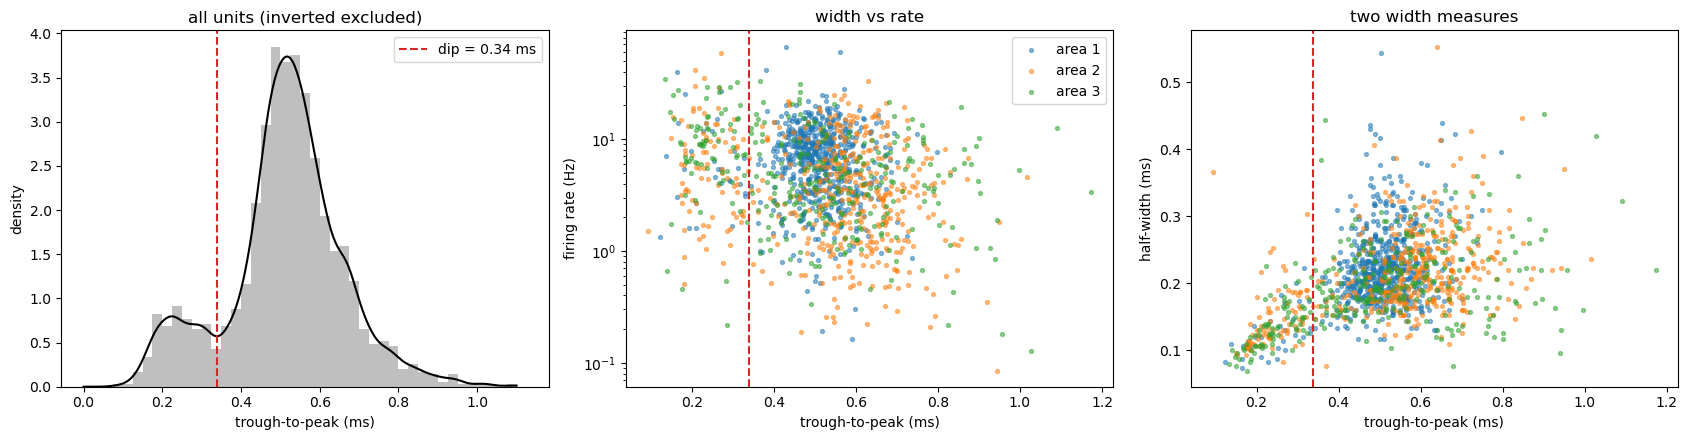

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
grid = np.linspace(0, 1.1, 400)
axs[0].hist(ok.trough_to_peak_ms, bins=np.arange(0, 1.15, 0.025), color="0.75", density=True)
axs[0].plot(grid, gaussian_kde(ok.trough_to_peak_ms, bw_method=0.15)(grid), color="k")
axs[0].axvline(THR, color="tab:red", ls="--", label=f"dip = {THR:.2f} ms")
axs[0].set(xlabel="trough-to-peak (ms)", ylabel="density", title="all units (inverted excluded)"); axs[0].legend()
for a in AREAS:
    g = ok[ok.area == a]
    axs[1].scatter(g.trough_to_peak_ms, g.rate_hz, s=8, alpha=0.5, color=AREA_COLORS[a], label=f"area {a}")
    axs[2].scatter(g.trough_to_peak_ms, g.half_width_ms, s=8, alpha=0.5, color=AREA_COLORS[a])
axs[1].axvline(THR, color="tab:red", ls="--"); axs[1].set(yscale="log", xlabel="trough-to-peak (ms)", ylabel="firing rate (Hz)", title="width vs rate"); axs[1].legend()
axs[2].axvline(THR, color="tab:red", ls="--"); axs[2].set(xlabel="trough-to-peak (ms)", ylabel="half-width (ms)", title="two width measures")
fig.tight_layout()

## 2. What the two classes look like

These are the average normalised waveforms of the narrow and broad units in each area (median ± interquartile range), aligned on the trough, plus the spike-train features of each class.
If the narrow units are FS cells, they should be narrow in every area **and** fire faster than the broad units.

trough_to_peak_ms  half_width_ms  rate_hz  cv_isi  \
area fs                                                               
1    broad                    0.508          0.220    7.013   1.796   
     narrow (FS)              0.255          0.120    5.410   1.700   
2    broad                    0.593          0.213    3.367   2.366   
     narrow (FS)              0.233          0.130    5.509   2.703   
3    broad                    0.555          0.200    3.858   2.128   
     narrow (FS)              0.237          0.130    8.927   1.910   

                  burst_fraction  
area fs                           
1    broad                 0.047  
     narrow (FS)           0.045  
2    broad                 0.006  
     narrow (FS)           0.028  
3    broad                 0.036  
     narrow (FS)           0.050

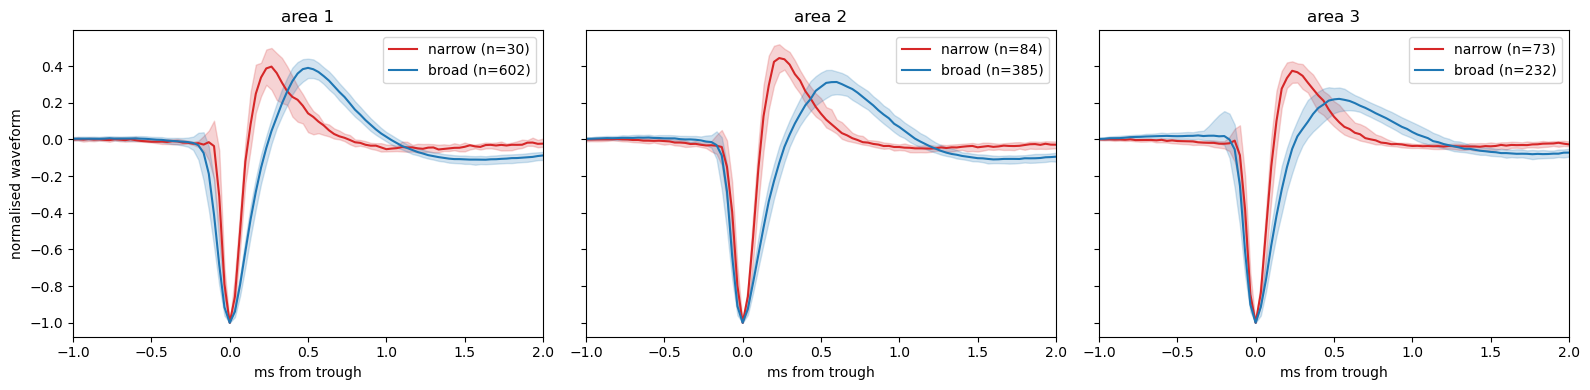

In [3]:
wfs = {}
for m in sorted(ok.mouse.unique()):
    rec = Recording.load(m)
    row = dict(zip(rec.cluster_ids, rec.waveforms))
    for _, u in ok[ok.mouse == m].iterrows():
        w = row[u.cluster_id].astype(float); w = w - np.median(w[:20]); w = w / -w.min()
        k = int(np.argmin(w)); w = np.roll(w, 42 - k)
        wfs[(m, u.cluster_id)] = w
t = (np.arange(128) - 42) / FS_WAVEFORM * 1000
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, a in zip(axs, AREAS):
    for cls, color in [(1.0, "tab:red"), (0.0, "tab:blue")]:
        sel = ok[(ok.area == a) & (ok.fs == cls)]
        W = np.array([wfs[(m, c)] for m, c in zip(sel.mouse, sel.cluster_id)])
        if len(W):
            q25, q50, q75 = np.percentile(W, [25, 50, 75], axis=0)
            ax.plot(t, q50, color=color, label=f"{'narrow' if cls else 'broad'} (n={len(W)})")
            ax.fill_between(t, q25, q75, color=color, alpha=0.2)
    ax.set(xlim=(-1, 2), xlabel="ms from trough", title=f"area {a}"); ax.legend()
axs[0].set_ylabel("normalised waveform")
fig.tight_layout()

feat = ok.groupby(["area", "fs"])[["trough_to_peak_ms", "half_width_ms", "rate_hz", "cv_isi", "burst_fraction"]].median()
feat.index = feat.index.set_levels(["broad", "narrow (FS)"], level=1)
feat.round(3)

## 3. FS fraction per mouse and area

Friedman p = 4.3e-05


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,3,18,0.0050,0.0149
area 1 vs area 3,1,18,0.0042,0.0125
area 2 vs area 3,3,18,0.0552,0.1656


mouse         1     2     3     4     5     6     7     8     9     10    11  \
      area                                                                     
% FS  1      0.0   0.0   9.0   0.0   0.0   0.0  18.0   0.0  12.0   5.0   0.0   
      2     14.0  25.0  15.0  17.0   9.0  10.0  14.0   9.0  44.0  20.0  16.0   
      3     29.0  11.0  17.0  20.0   0.0  50.0  42.0  29.0  20.0  31.0  17.0   
units 1     59.0  40.0  47.0  34.0  58.0  33.0  34.0  33.0  49.0  21.0  16.0   
      2     21.0  20.0  26.0   6.0  55.0  21.0  28.0  32.0  32.0   5.0  37.0   
      3      7.0  19.0  12.0  15.0  12.0  10.0  24.0  24.0  45.0  13.0  18.0   

mouse         12    13    14    15    16    17    18  
      area                                            
% FS  1      0.0   0.0  67.0  15.0   0.0   0.0   7.0  
      2     25.0   7.0  20.0  15.0  24.0  20.0  27.0  
      3     27.0  19.0  20.0  20.0  29.0  23.0  42.0  
units 1     19.0  69.0  15.0  13.0  54.0  24.0  14.0  
      2     12.0  28.0  10.0  33.0  37.0  44.0  22.0  
      3     11.0  16.0  15.0  15.0   7.0  30.0  12.0

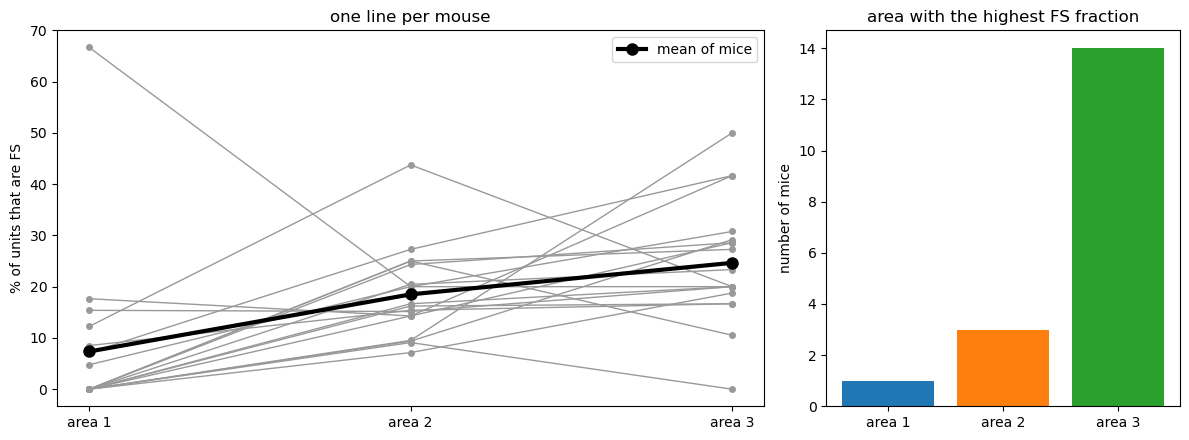

In [4]:
per_mouse, friedman, wilc = per_mouse_tests(ok, "fs")
counts = ok.groupby(["mouse", "area"]).size().unstack()
highest = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, 100 * row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, 100 * per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="% of units that are FS", title="one line per mouse"); a1.legend()
a2.bar([f"area {a}" for a in AREAS], highest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title="area with the highest FS fraction")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
display(wilc.round(4))
pd.concat({"% FS": (100 * per_mouse).round(0), "units": counts}, axis=1).T

## 4. Mean and 95% CI

The fraction FS is the mean of a 0/1 label over units, with a hierarchical bootstrap over mice, then units.

In [5]:
t_main, boot = area_bootstrap(ok, "fs")
(t_main.assign(estimate=100 * t_main.estimate, ci_low=100 * t_main.ci_low, ci_high=100 * t_main.ci_high)
 .rename(columns={"estimate": "% FS (or difference)"}).round(2))

,% FS (or difference),ci_low,ci_high,p (diff = 0)
area 1,4.75,1.20,10.00,NaN
area 2,17.91,12.50,24.16,NaN
area 3,23.93,17.56,31.04,NaN
area 1 − area 2,-13.16,-19.53,-6.57,0.0
area 1 − area 3,-19.19,-26.92,-11.61,0.0
area 2 − area 3,-6.02,-15.13,3.12,0.2


## 5. Robustness to the definition of "fast-spiking"

In [6]:
def gmm_fs(df):
    # two Gaussians fitted to the trough-to-peak times; FS = units assigned to the narrow one
    X = df[["trough_to_peak_ms"]].to_numpy()
    g = GaussianMixture(2, n_init=10, random_state=0).fit(X)
    return (g.predict(X) == int(np.argmin(g.means_[:, 0]))).astype(float)

rate_med = ok.rate_hz.median()
defs = {
    f"main: trough-to-peak < dip ({THR:.2f} ms)": ok.fs,
    "trough-to-peak < 0.30 ms": (ok.trough_to_peak_ms < 0.30).astype(float),
    "trough-to-peak < 0.40 ms": (ok.trough_to_peak_ms < 0.40).astype(float),
    f"narrow AND rate > overall median ({rate_med:.1f} Hz)": ((ok.fs == 1) & (ok.rate_hz > rate_med)).astype(float),
    "Gaussian mixture on trough-to-peak": gmm_fs(ok),
}
rows = {}
for lab, lab_fs in defs.items():
    d = ok.assign(fs_alt=np.asarray(lab_fs))
    pm, fr, w = per_mouse_tests(d, "fs_alt")
    rows[lab] = {**{f"area {a} % FS": 100 * d[d.area == a].fs_alt.mean() for a in AREAS},
                 "highest (pooled)": f"area {d.groupby('area').fs_alt.mean().idxmax()}",
                 "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index()),
                 "Wilcoxon p 3 vs 2": w.loc["area 2 vs area 3", "wilcoxon p"],
                 "Wilcoxon p 3 vs 1": w.loc["area 1 vs area 3", "wilcoxon p"]}
robust = pd.DataFrame(rows).T
robust

,area 1 % FS,area 2 % FS,area 3 % FS,highest (pooled),highest in n mice,Wilcoxon p 3 vs 2,Wilcoxon p 3 vs 1
main: trough-to-peak < dip (0.34 ms),4.746835,17.910448,23.934426,area 3,"{1: 1, 2: 3, 3: 14}",0.055213,0.004179
trough-to-peak < 0.30 ms,3.797468,14.498934,19.672131,area 3,"{1: 1, 2: 7, 3: 10}",0.469113,0.004173
trough-to-peak < 0.40 ms,7.753165,21.321962,33.114754,area 3,"{1: 1, 2: 4, 3: 13}",0.008965,0.001045
narrow AND rate > overall median (5.4 Hz),2.373418,9.168443,18.032787,area 3,"{1: 1, 2: 4, 3: 13}",0.006577,0.00264
Gaussian mixture on trough-to-peak,3.322785,13.646055,18.360656,area 3,"{1: 1, 2: 7, 3: 10}",0.408044,0.004841


## 6. Answer for the questionnaire

In [7]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = (100 * t_main.iloc[:3, :3]).copy()
answer.columns = ["Mean", "CI low", "CI high"]
answer["95% C.I."] = answer.apply(lambda r: f"[{r['CI low']:.1f}, {r['CI high']:.1f}]", axis=1)
answer["Units"] = "% of units"
answer = answer[["Mean", "95% C.I.", "Units"]].round(1)
answer.to_csv(RESULTS_DIR / "q07_answer.csv")
display(answer)

d = t_main.estimate
wb = wilc["wilcoxon p (Bonferroni)"]
n_thr = int((robust["highest (pooled)"] == "area 3").sum())
n_sig = int((3 * robust["Wilcoxon p 3 vs 2"].astype(float) < 0.05).sum())
expl = (
    f"Putative fast-spiking (FS) interneurons were identified from the average spike waveform. The trough-to-peak time of "
    f"all units was bimodal, with a narrow group (FS-like) and a broad group (pyramidal-like); units below the dip of "
    f"this distribution ({THR:.2f} ms) were classified as FS. Units with inverted (positive-dominant) waveforms "
    f"({int(units.inverted.sum())} of {len(units)}) were excluded because their trough-to-peak time is not "
    f"interpretable. Density is the percentage of each area's units classified as FS, with a hierarchical bootstrap CI "
    f"(mice, then units). Area 3 had the highest FS fraction ({100 * d['area 3']:.0f}% vs {100 * d['area 2']:.0f}% in "
    f"area 2 and {100 * d['area 1']:.0f}% in area 1) and was highest in {int(highest[3])} of 18 mice. It exceeded area 1 "
    f"(paired Wilcoxon p = {wb['area 1 vs area 3']:.3f}) but not area 2 (p = {wb['area 2 vs area 3']:.2f}); with fixed "
    f"thresholds (0.30 and 0.40 ms), a Gaussian mixture on trough-to-peak and a criterion requiring both a narrow spike "
    f"and an above-median firing rate, area 3 stayed numerically highest ({n_thr} of {len(robust)} definitions) but "
    f"exceeded area 2 significantly in only {n_sig} of them. Pairwise p-values are Bonferroni-corrected for the three "
    f"comparisons. Because no area was reliably above both others, I answer not enough data / no differences."
)
print(len(expl.split()), "words")
print(expl)
record_answer(7, choice=3,                                   # 3 = not enough data / no differences
              rows=[(f"{r.Mean:.1f}", r["95% C.I."], r.Units) for _, r in answer.iterrows()], explanation=expl)
record_meta(7, confidence=4, consensus=3)
print(fill_pdf())


,Mean,95% C.I.,Units
area 1,4.7,"[1.2, 10.0]",% of units
area 2,17.9,"[12.5, 24.2]",% of units
area 3,23.9,"[17.6, 31.0]",% of units


188 words
Putative fast-spiking (FS) interneurons were identified from the average spike waveform. The trough-to-peak time of all units was bimodal, with a narrow group (FS-like) and a broad group (pyramidal-like); units below the dip of this distribution (0.34 ms) were classified as FS. Units with inverted (positive-dominant) waveforms (43 of 1449) were excluded because their trough-to-peak time is not interpretable. Density is the percentage of each area's units classified as FS, with a hierarchical bootstrap CI (mice, then units). Area 3 had the highest FS fraction (24% vs 18% in area 2 and 5% in area 1) and was highest in 14 of 18 mice. It exceeded area 1 (paired Wilcoxon p = 0.013) but not area 2 (p = 0.17); with fixed thresholds (0.30 and 0.40 ms), a Gaussian mixture on trough-to-peak and a criterion requiring both a narrow spike and an above-median firing rate, area 3 stayed numerically highest (5 of 5 definitions) but exceeded area 2 significantly in only 2 of them. Pairwise p-

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**Not enough data / no differences.** Area 3 has the highest fraction of putative FS interneurons (about 24% vs 18% in area 2 and 5% in area 1), and area 1 is clearly the lowest.
But area 3 is **not** reliably above area 2: the corrected Wilcoxon p is ≈ 0.17, and only some of the alternative definitions separate them.
Because no area reliably beats both others, the answer is "no differences". Area 3 remains the most likely candidate.
